# 05 — Independent test evaluation, experiments E1–E7, interpretability
All numbers come from the frozen benchmark predictions in `artifacts/predictions/` (2025 targets never used for
any fitting or selection).

In [1]:
# --- Setup: locate the project root and import the package --------------------
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from air_quality.config import load_config, setup_logging
cfg = load_config(ROOT / "config.yaml"); setup_logging(cfg, "notebooks")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
FIG = cfg.path("figures_dir"); MET = cfg.path("metrics_dir")
print("Project root:", ROOT)

Project root: /Users/dannieey/Desktop/ML_final


In [2]:
from air_quality.evaluation import run_evaluation
from air_quality.explainability import run_explainability
ev = run_evaluation(cfg); ex = run_explainability(cfg)
comp = pd.read_csv(MET / "model_comparison.csv")
display(comp[["model", "feature_config", "validation_mae", "test_mae", "test_rmse", "test_r2", "test_smape_pct",
              "test_bias", "test_mae_improvement_pct", "test_n"]].round(3))

/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


2026-11-17 07:46:29 | INFO    | Evaluation tables and figures written to /Users/dannieey/Desktop/ML_final/artifacts/metrics and /Users/dannieey/Desktop/ML_final/artifacts/figures


/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/

/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/

/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/

/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/

... (9 outputs left out)

2026-11-17 07:47:25 | INFO    | Permutation importance computed for svr


2026-11-17 07:48:21 | INFO    | Permutation importance computed for ensemble


2026-11-17 07:48:22 | INFO    | E6 interpretability done (skipped (shap not installed; optional))


,model,feature_config,validation_mae,test_mae,test_rmse,test_r2,test_smape_pct,test_bias,test_mae_improvement_pct,test_n
0,ensemble,full_weather,2.227,3.015,4.655,0.414,61.770,0.625,14.231,346
1,xgboost,full_weather,2.249,3.148,4.768,0.385,63.808,0.825,10.458,346
2,svr,full_weather,2.261,2.959,4.665,0.411,60.488,0.425,15.835,346
3,random_forest,full_weather,2.352,3.120,4.793,0.378,64.006,0.626,11.242,346
4,ridge,full_weather,2.637,3.715,5.271,0.248,71.642,1.217,-5.668,346
5,persistence,pm25_mean_24h,3.711,3.516,6.059,0.006,63.825,0.002,0.000,346


## E1 — Model comparison (same eligible test dates)

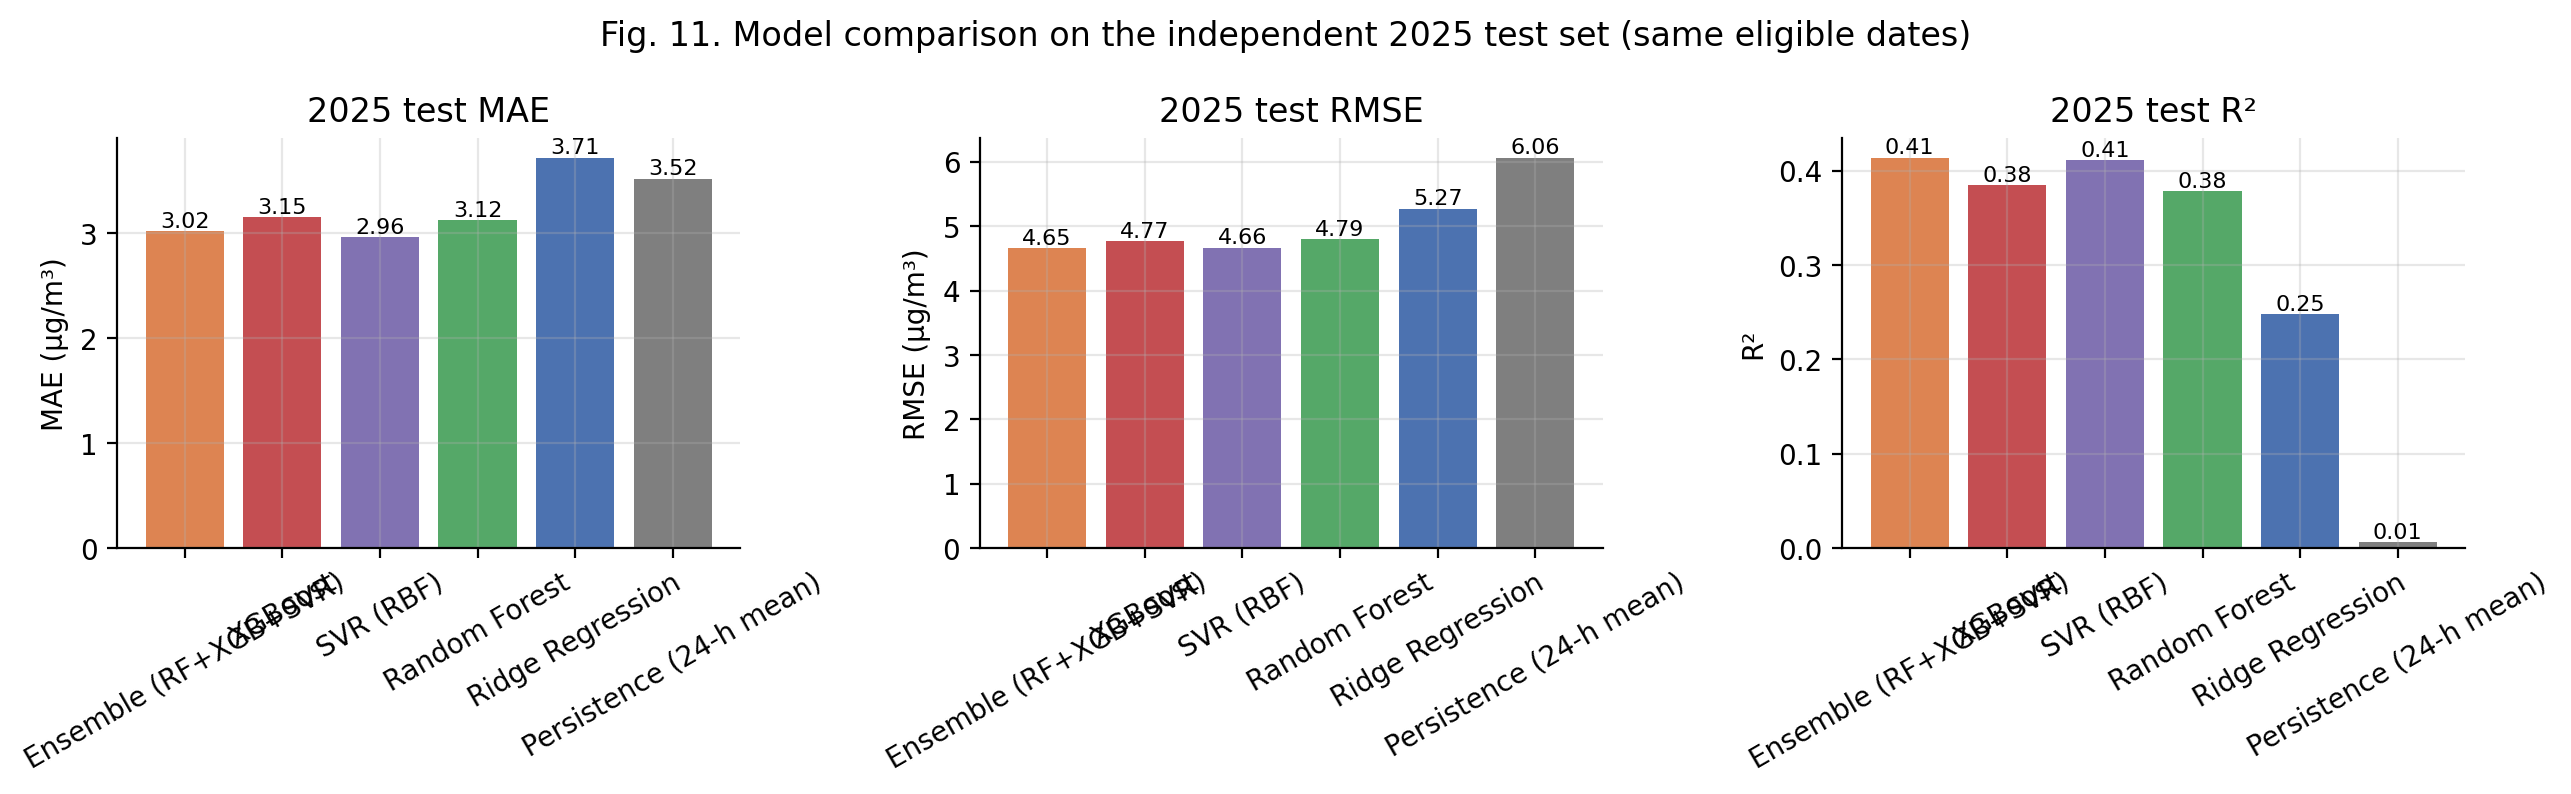

The validation-selected model is ensemble (full_weather). On the 2025 test it obtained MAE = 3.02 µg/m³ (RMSE 4.65, R² 0.414) compared with MAE = 3.52 µg/m³ for persistence (14.2% change in MAE).
Lowest test MAE overall: svr (2.96); reported for transparency only — selection used validation.


In [3]:
display(Image(FIG / "11_model_comparison.png"))
best = ev["selection"]["best"]; b = comp[comp.model == best["model"]].iloc[0]; p = comp[comp.model == "persistence"].iloc[0]
print(f"The validation-selected model is {best['model']} ({best['feature_config']}). On the 2025 test it obtained "
      f"MAE = {b.test_mae:.2f} µg/m³ (RMSE {b.test_rmse:.2f}, R² {b.test_r2:.3f}) compared with "
      f"MAE = {p.test_mae:.2f} µg/m³ for persistence ({b.test_mae_improvement_pct:.1f}% change in MAE).")
lowest = comp.loc[comp.test_mae.idxmin()]
print(f"Lowest test MAE overall: {lowest.model} ({lowest.test_mae:.2f}); reported for transparency only — selection used validation.")

## E2 — Effect of feature engineering (basic → lag → lag + rolling)

,model,feature_config,test_mae,validation_mae,test_r2,validation_r2,test_rmse,validation_rmse
0,ensemble,basic,3.108,3.105,0.414,0.461,4.652,4.678
1,ensemble,full,2.970,3.091,0.365,0.451,4.845,4.722
2,ensemble,lag,2.967,3.099,0.359,0.454,4.868,4.706
3,random_forest,basic,3.141,3.116,0.398,0.449,4.716,4.729
4,random_forest,full,3.080,3.142,0.362,0.463,4.855,4.668
5,random_forest,lag,3.030,3.118,0.333,0.468,4.963,4.649
6,ridge,basic,3.337,3.405,0.385,0.425,4.767,4.829
7,ridge,full,3.129,3.225,0.372,0.466,4.818,4.658
8,ridge,lag,3.253,3.342,0.359,0.448,4.866,4.732
9,svr,basic,3.117,3.155,0.399,0.429,4.714,4.815


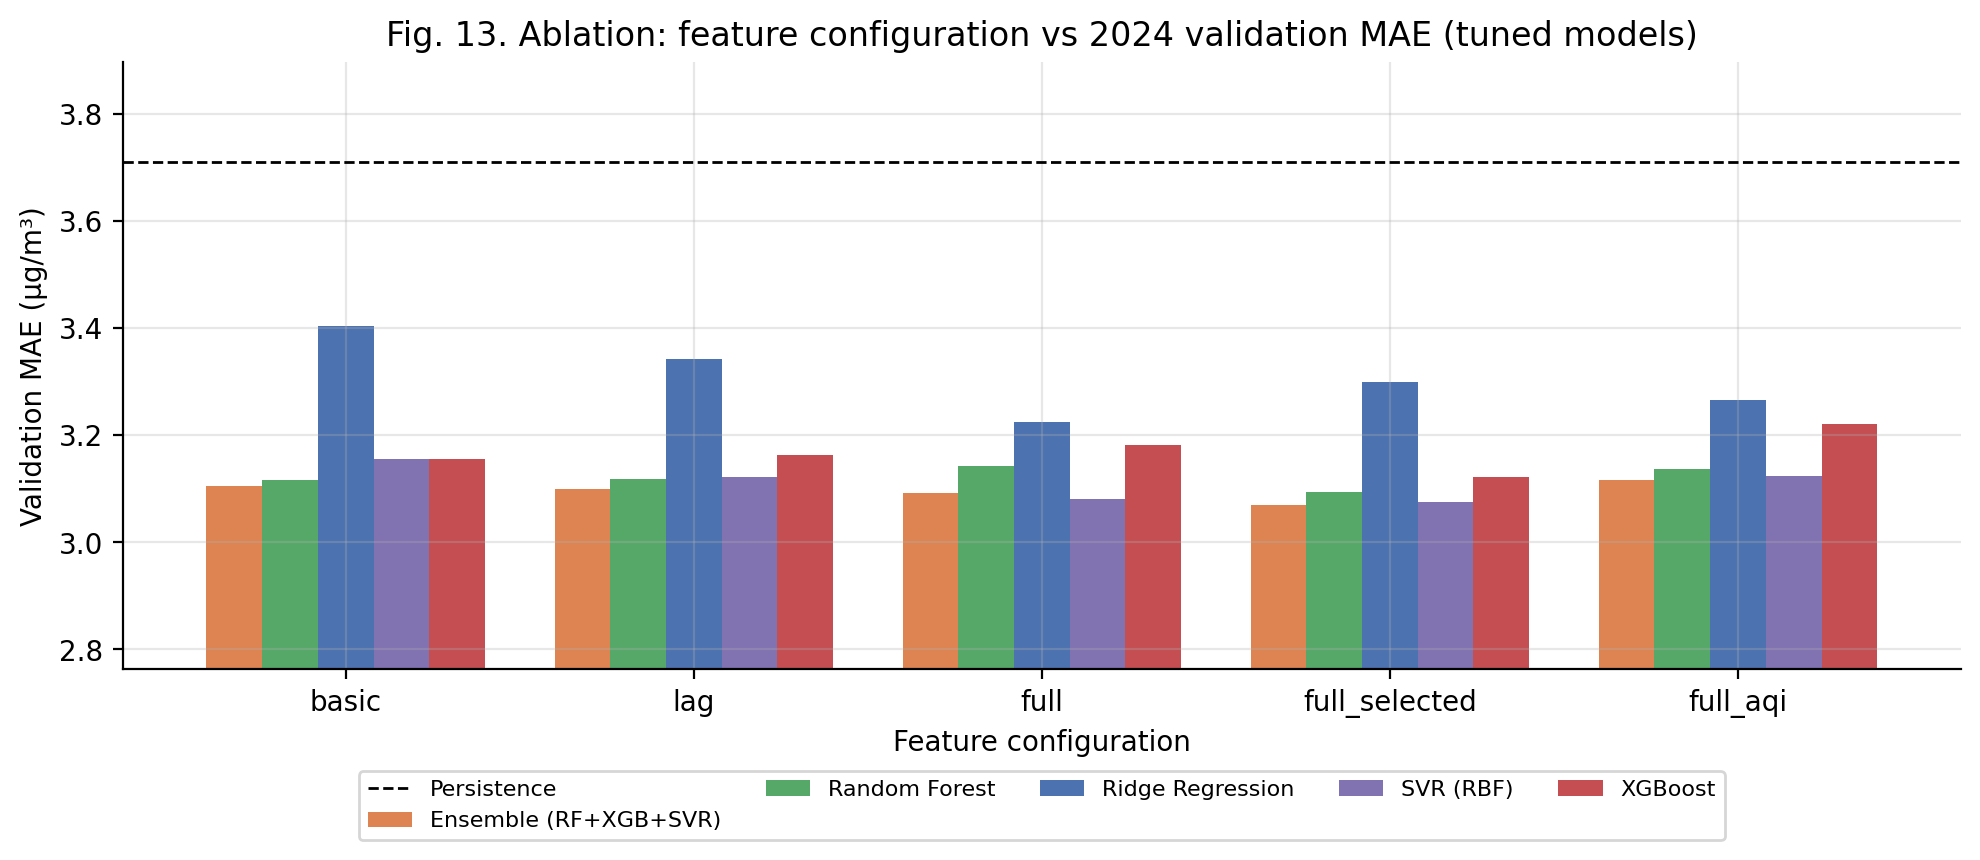

In [4]:
e2 = pd.read_csv(MET / "E2_feature_engineering.csv"); display(e2.round(3))
display(Image(FIG / "13_ablation_feature_configs.png"))

## E3 — Feature selection

In [5]:
display(pd.read_csv(MET / "E3_feature_selection.csv").round(3))

,model,feature_config,stage,mae,rmse,r2,n_features_in,n_features_used
0,ridge,full,validation,3.225,4.658,0.465,43,43
1,ridge,full,test,3.129,4.818,0.372,43,43
2,random_forest,full,validation,3.142,4.668,0.463,43,43
3,random_forest,full,test,3.080,4.855,0.362,43,43
4,xgboost,full,validation,3.182,4.700,0.456,43,43
5,xgboost,full,test,2.998,4.801,0.376,43,43
6,svr,full,validation,3.080,5.026,0.378,43,43
7,svr,full,test,2.957,5.035,0.314,43,43
8,ensemble,full,validation,3.091,4.722,0.451,43,43
9,ensemble,full,test,2.971,4.845,0.365,43,43


## E4 — Default vs tuned hyperparameters

In [6]:
display(pd.read_csv(MET / "E4_hyperparameter_optimization.csv").round(3))

,model,feature_config,stage,default,tuned,mae_change_tuned_minus_default
0,ensemble,basic,test,3.178,3.108,-0.070
1,ensemble,basic,validation,3.305,3.105,-0.200
2,ensemble,full,test,3.446,2.971,-0.476
3,ensemble,full,validation,3.184,3.091,-0.093
4,ensemble,full_aqi,test,3.327,2.988,-0.339
...,...,...,...,...,...,...
65,xgboost,full_weather,validation,2.410,2.249,-0.161
66,xgboost,full_weather_past,test,3.832,3.040,-0.792
67,xgboost,full_weather_past,validation,3.187,2.956,-0.231
68,xgboost,lag,test,3.481,2.961,-0.520


## E5 — Elevated-pollution days
Thresholds: (i) 90th percentile of **training** daily targets; (ii) WHO (2021) 24-h AQG level of 15 µg/m³.

,model,threshold_name,threshold_ugm3,n_elevated_days,mae_elevated,rmse_elevated,bias_elevated,mae_non_elevated,n_non_elevated_days
0,ensemble,train_q90,13.223,33,9.937,11.617,-9.547,2.285,313
1,ensemble,WHO_24h_15,15.000,23,11.584,13.125,-11.584,2.405,323
2,persistence,train_q90,13.223,33,10.545,12.539,-7.787,2.774,313
3,persistence,WHO_24h_15,15.000,23,11.343,13.279,-9.602,2.958,323
4,random_forest,train_q90,13.223,33,10.382,12.250,-10.237,2.355,313
5,random_forest,WHO_24h_15,15.000,23,12.463,13.996,-12.463,2.455,323
6,ridge,train_q90,13.223,33,9.779,11.584,-9.237,3.075,313
7,ridge,WHO_24h_15,15.000,23,11.179,12.987,-11.179,3.183,323
8,svr,train_q90,13.223,33,9.832,11.430,-8.852,2.234,313
9,svr,WHO_24h_15,15.000,23,10.922,12.605,-10.773,2.392,323


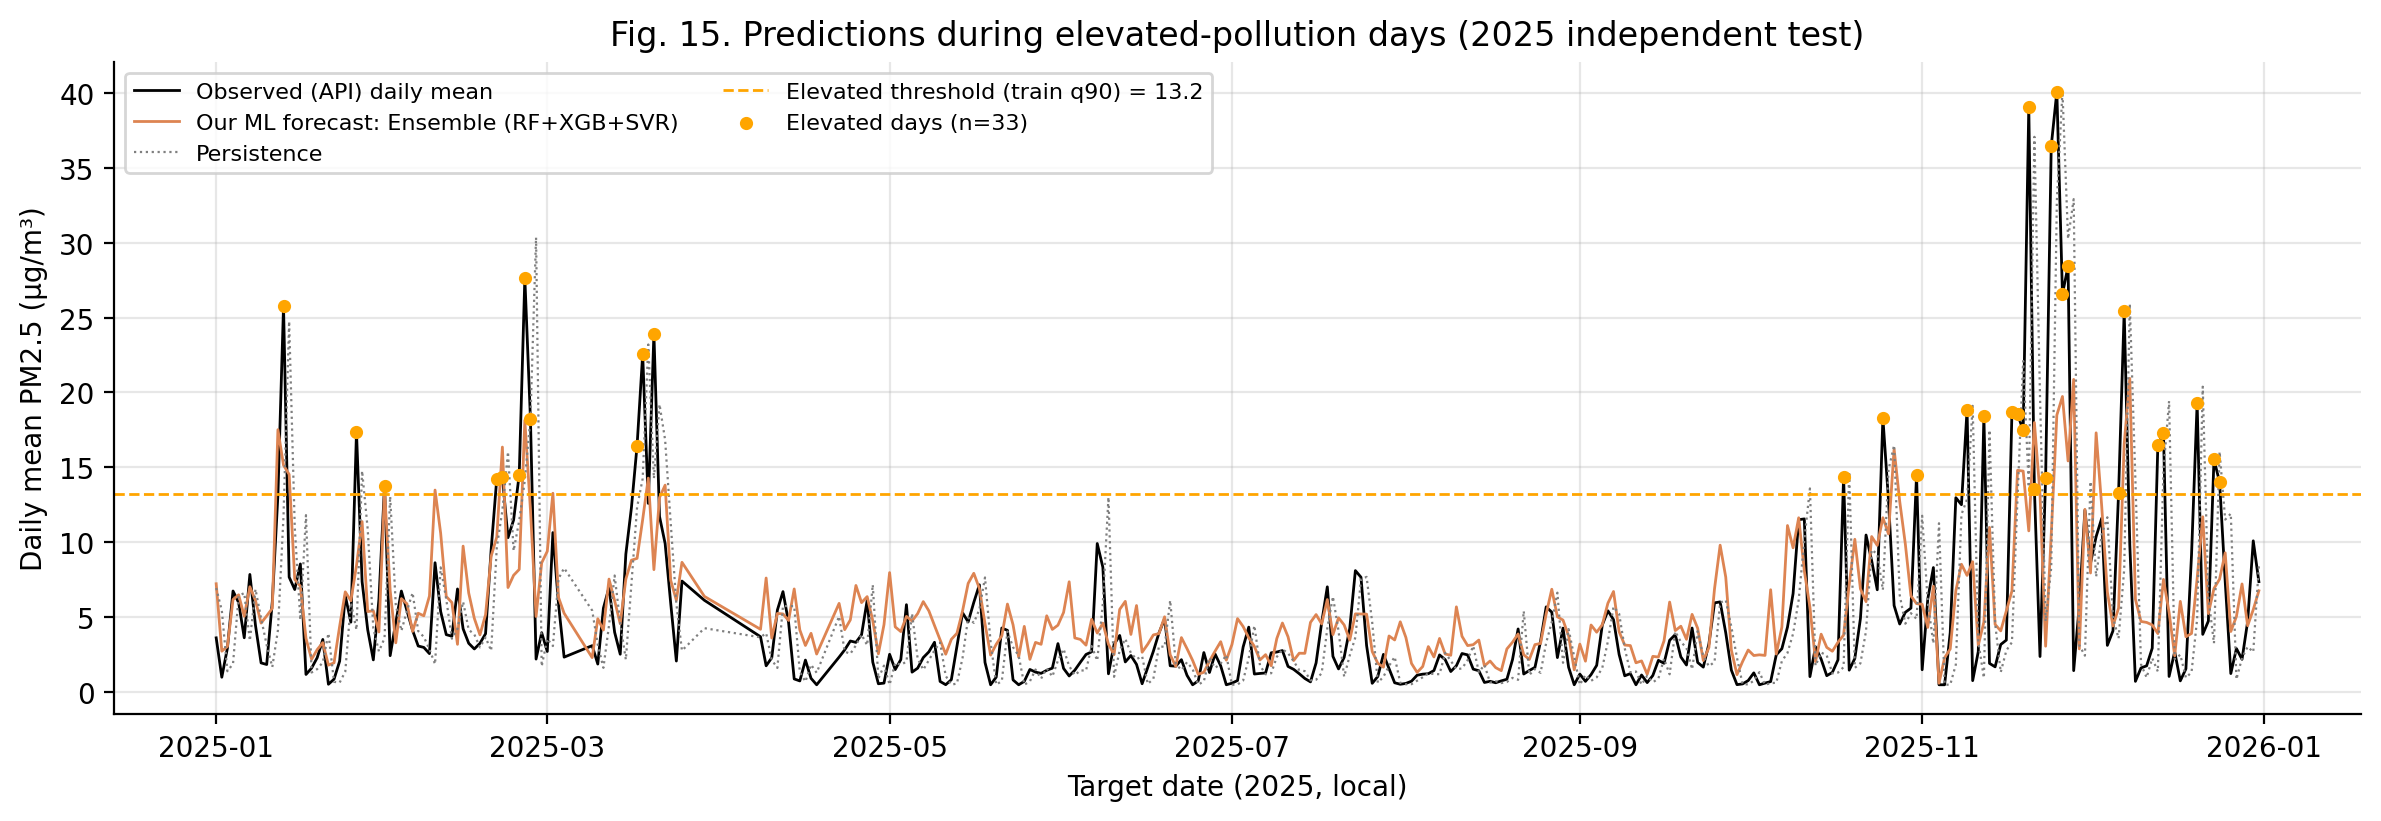

Number of elevated test days (train q90): 33. 


In [7]:
e5 = pd.read_csv(MET / "E5_elevated_pollution.csv"); display(e5.round(3))
display(Image(FIG / "15_elevated_pollution_predictions.png"))
n = e5[e5.threshold_name.str.startswith("train")].n_elevated_days.iloc[0]
print(f"Number of elevated test days (train q90): {n}. {'Small sample — interpret with caution.' if n < 30 else ''}")

## E6 — Interpretability (associational, not causal)

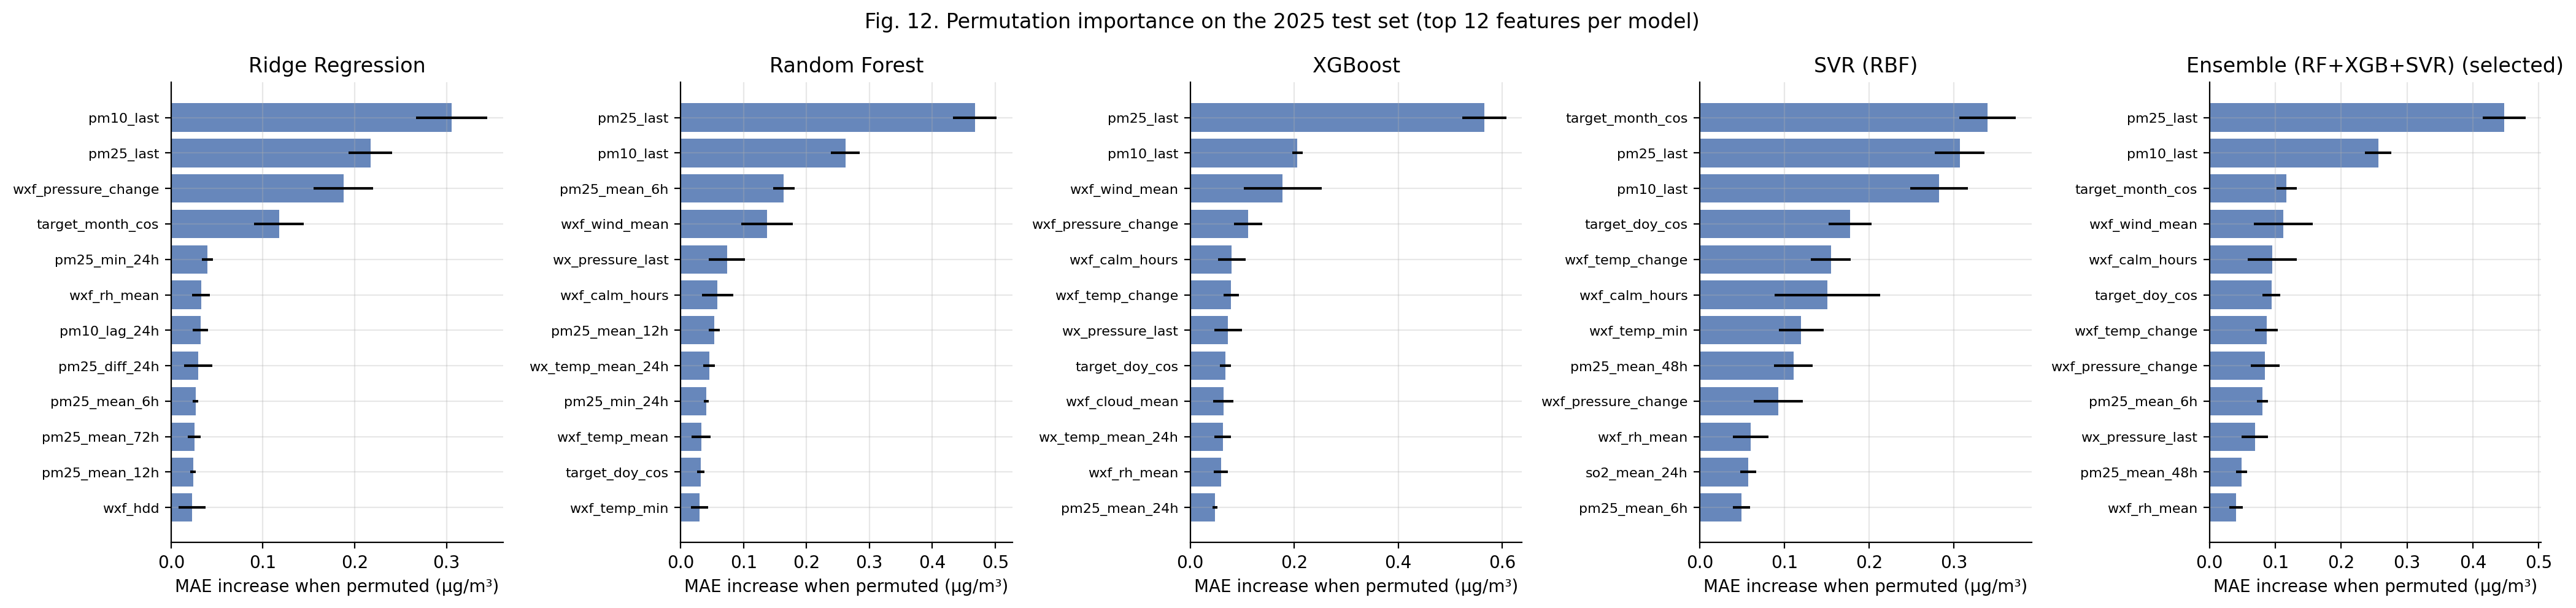

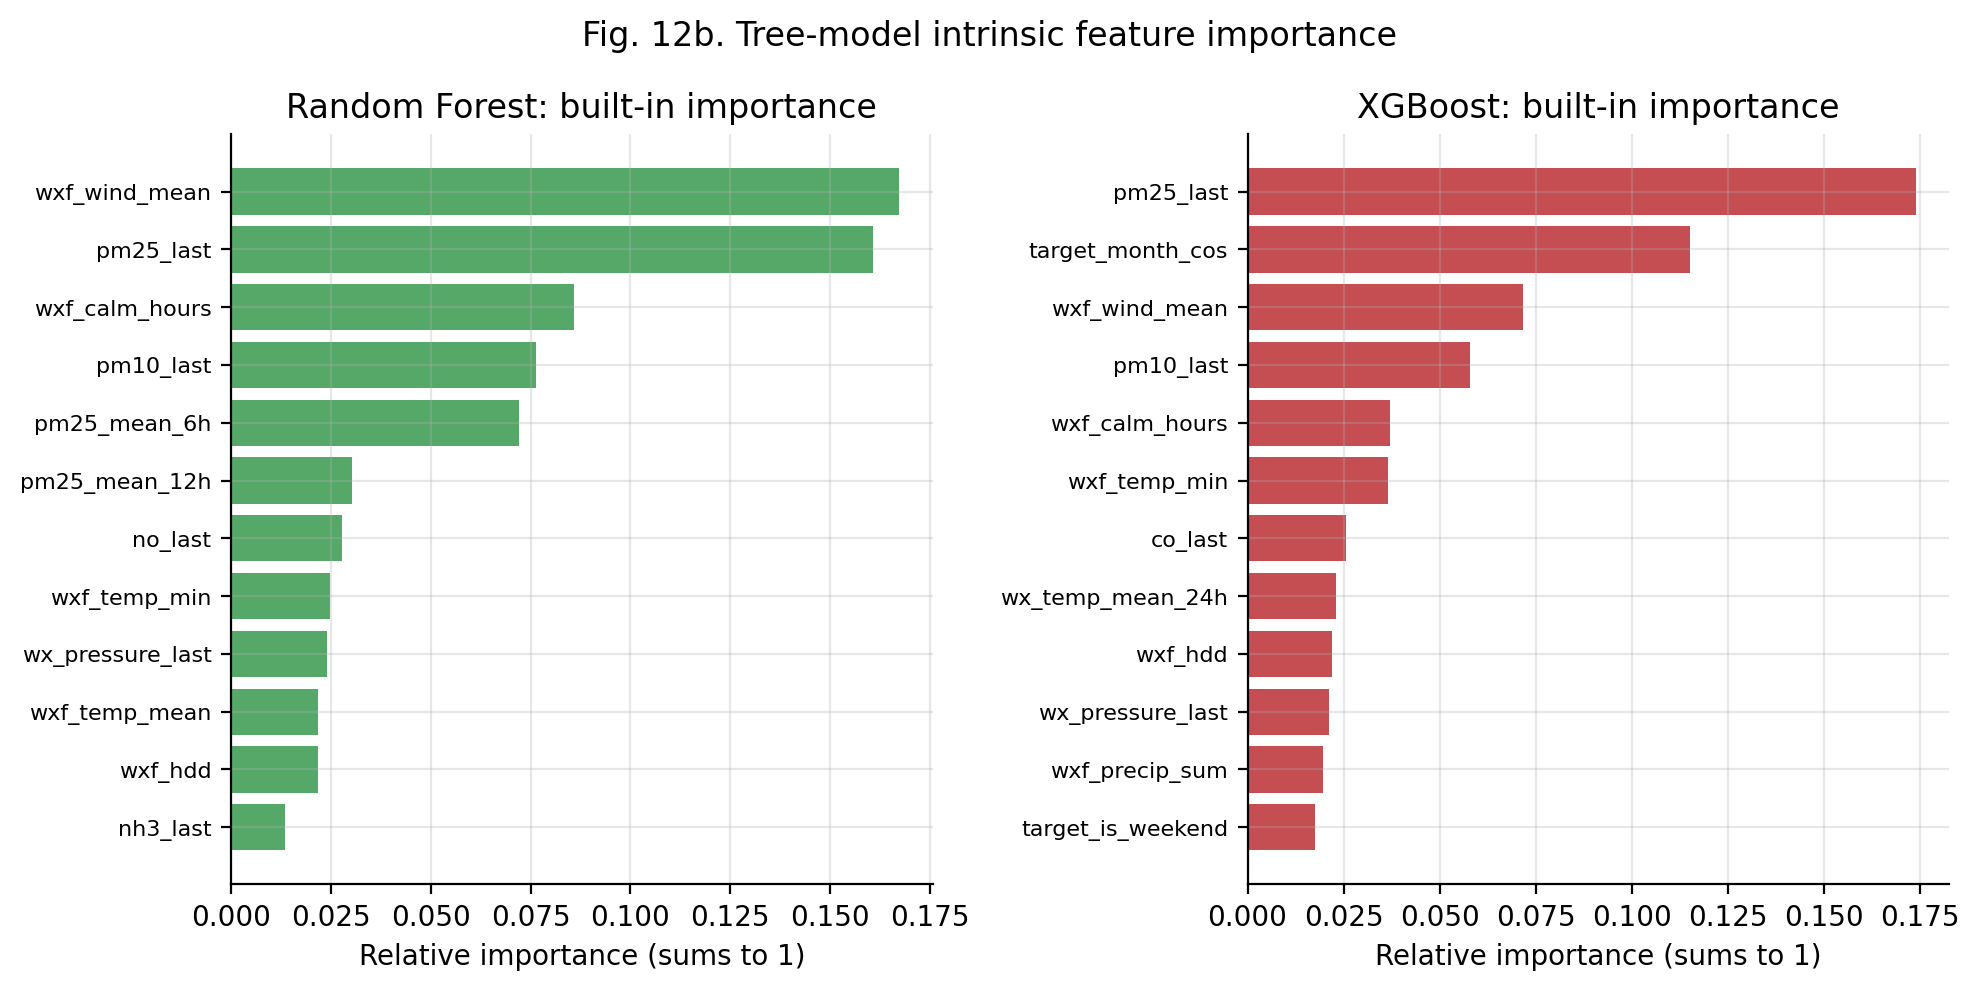

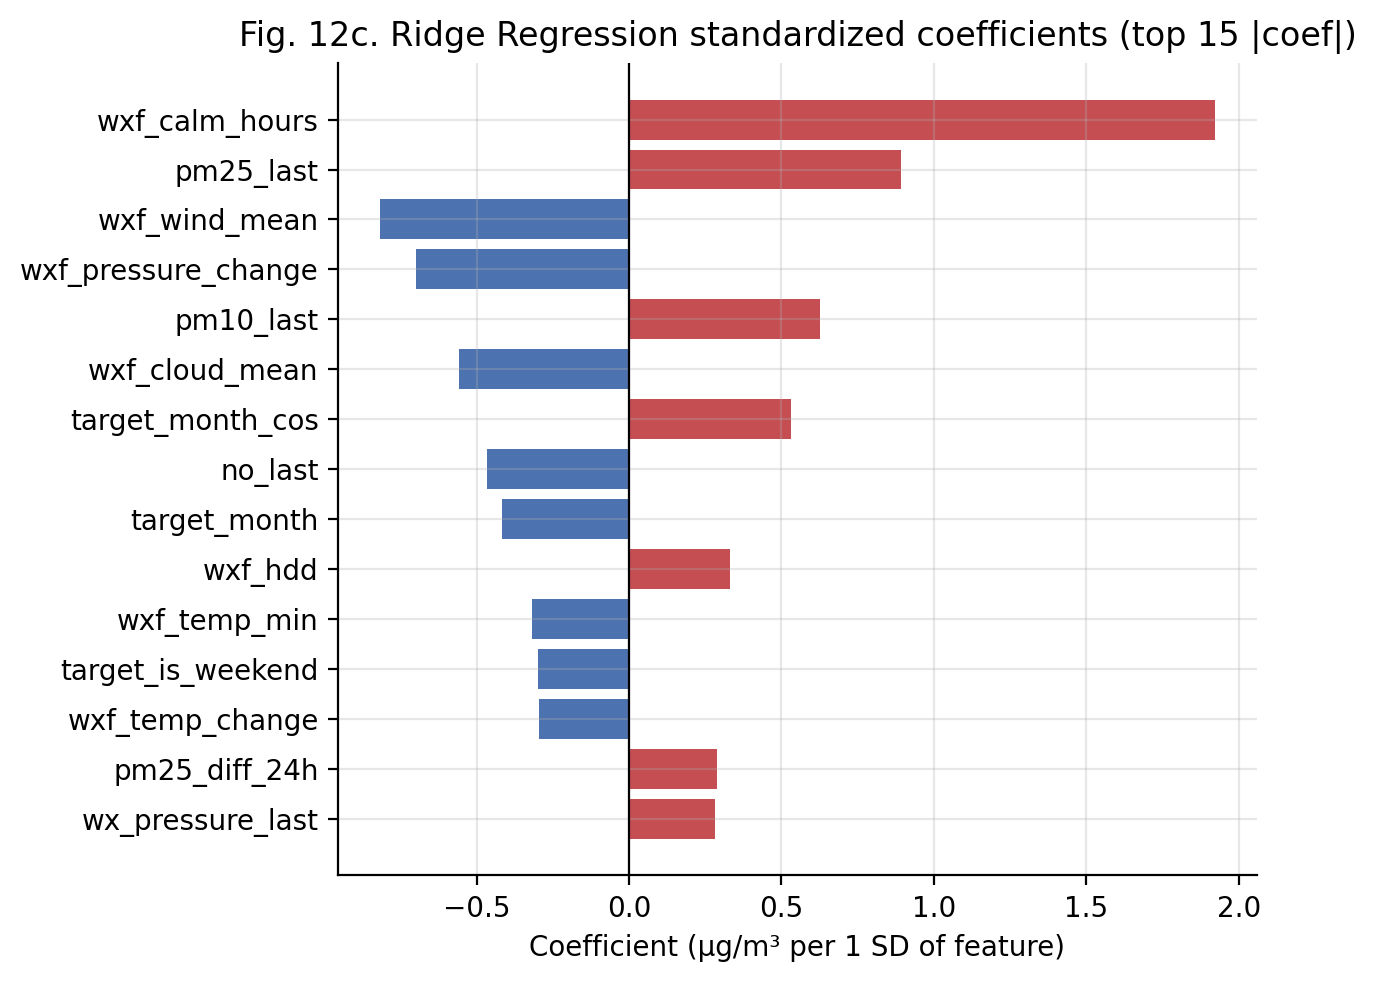

Top features (best model, permutation on 2025 test): [{'feature': 'pm25_last', 'mae_increase_mean': 0.4474774911834832}, {'feature': 'pm10_last', 'mae_increase_mean': 0.25613105875004627}, {'feature': 'target_month_cos', 'mae_increase_mean': 0.11724097351390968}, {'feature': 'wxf_wind_mean', 'mae_increase_mean': 0.1123463755877085}, {'feature': 'wxf_calm_hours', 'mae_increase_mean': 0.09550669027757279}, {'feature': 'target_doy_cos', 'mae_increase_mean': 0.09423204035217574}, {'feature': 'wxf_temp_change', 'mae_increase_mean': 0.08679691110833976}, {'feature': 'wxf_pressure_change', 'mae_increase_mean': 0.08468301667717837}, {'feature': 'pm25_mean_6h', 'mae_increase_mean': 0.08029115537875042}, {'feature': 'wx_pressure_last', 'mae_increase_mean': 0.06920292288061156}]


In [8]:
display(Image(FIG / "12_feature_importance_permutation.png"))
for f in ["12b_feature_importance_trees.png", "12c_ridge_coefficients.png", "12d_shap_summary.png"]:
    if (FIG / f).exists(): display(Image(FIG / f))
print("Top features (best model, permutation on 2025 test):", ex["top_permutation_features_best_model"])

## E7 — Robustness across months, seasons and heating periods

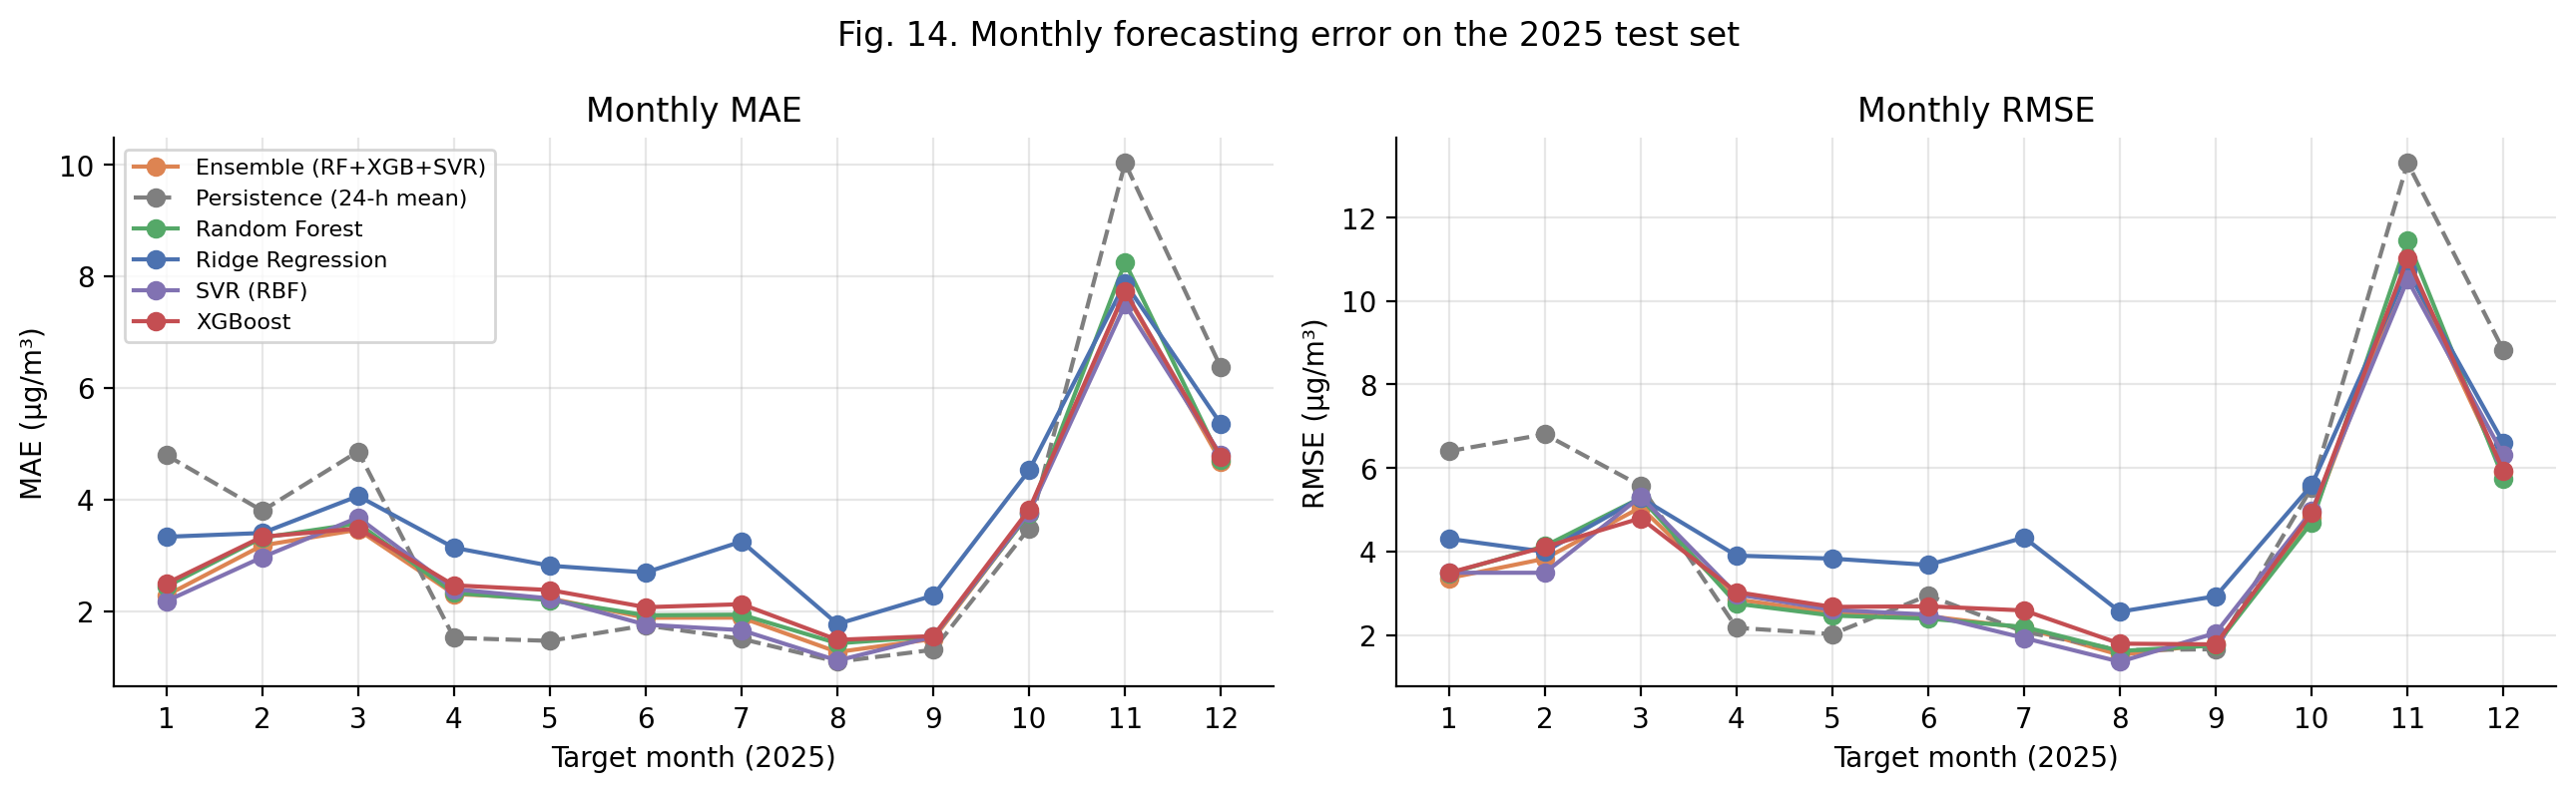

model,ensemble,persistence,random_forest,ridge,svr,xgboost
season,,,,,,
Autumn,4.32,4.93,4.50,4.89,4.26,4.36
Spring,2.62,2.51,2.65,3.28,2.71,2.73
Summer,1.68,1.44,1.76,2.57,1.51,1.89
Winter,3.39,5.03,3.49,4.05,3.33,3.54


model,ensemble,persistence,random_forest,ridge,svr,xgboost
heating,,,,,,
Heating,4.27,5.70,4.42,4.86,4.26,4.37
Non-heating,1.85,1.48,1.91,2.64,1.75,2.01


In [9]:
display(Image(FIG / "14_monthly_error.png"))
display(pd.read_csv(MET / "E7_seasonal_errors.csv").pivot(index="season", columns="model", values="mae").round(2))
display(pd.read_csv(MET / "E7_heating_errors.csv").pivot(index="heating", columns="model", values="mae").round(2))

## Error analysis

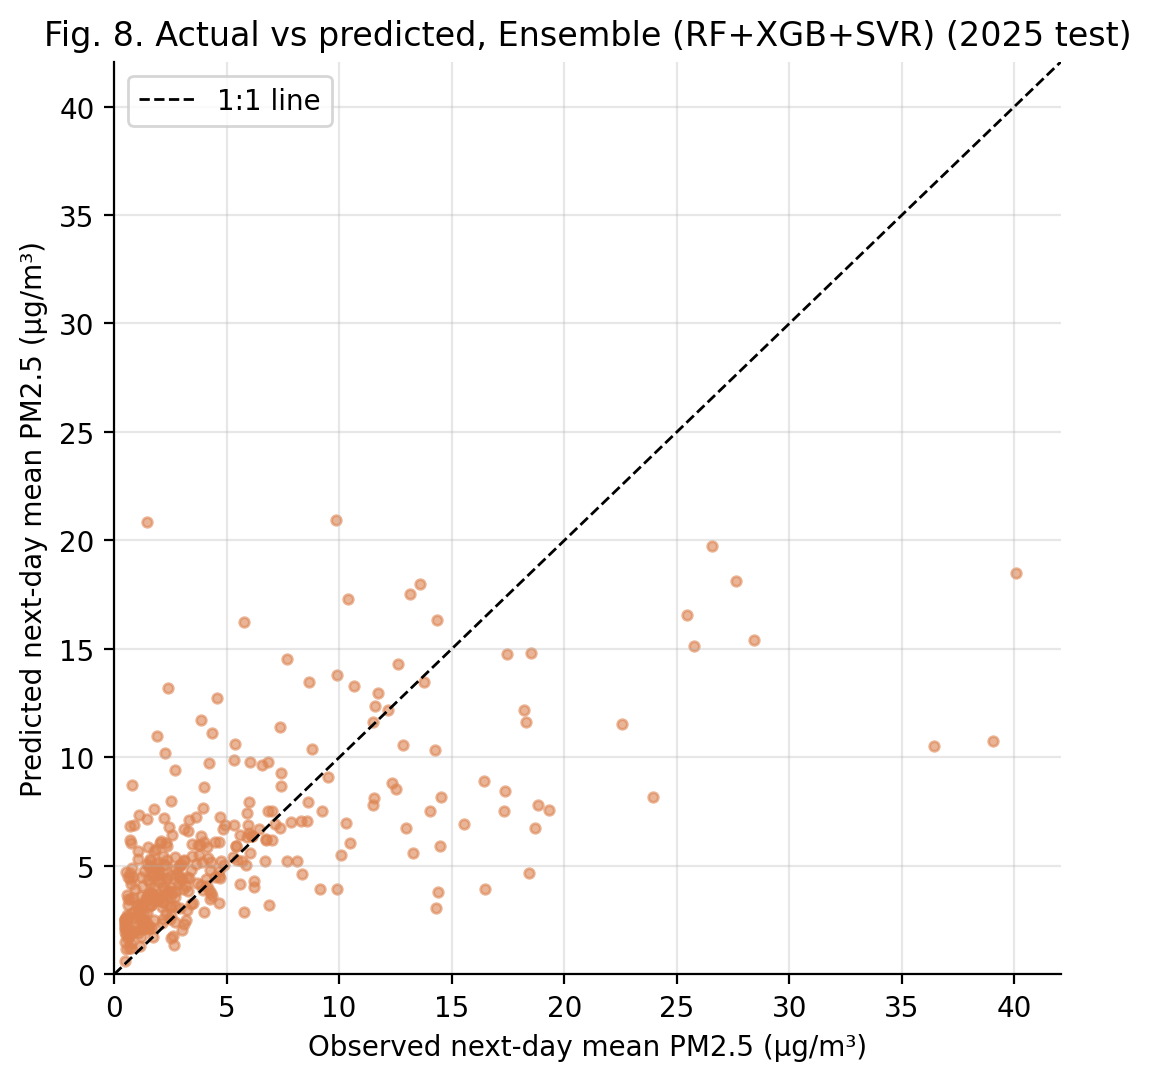

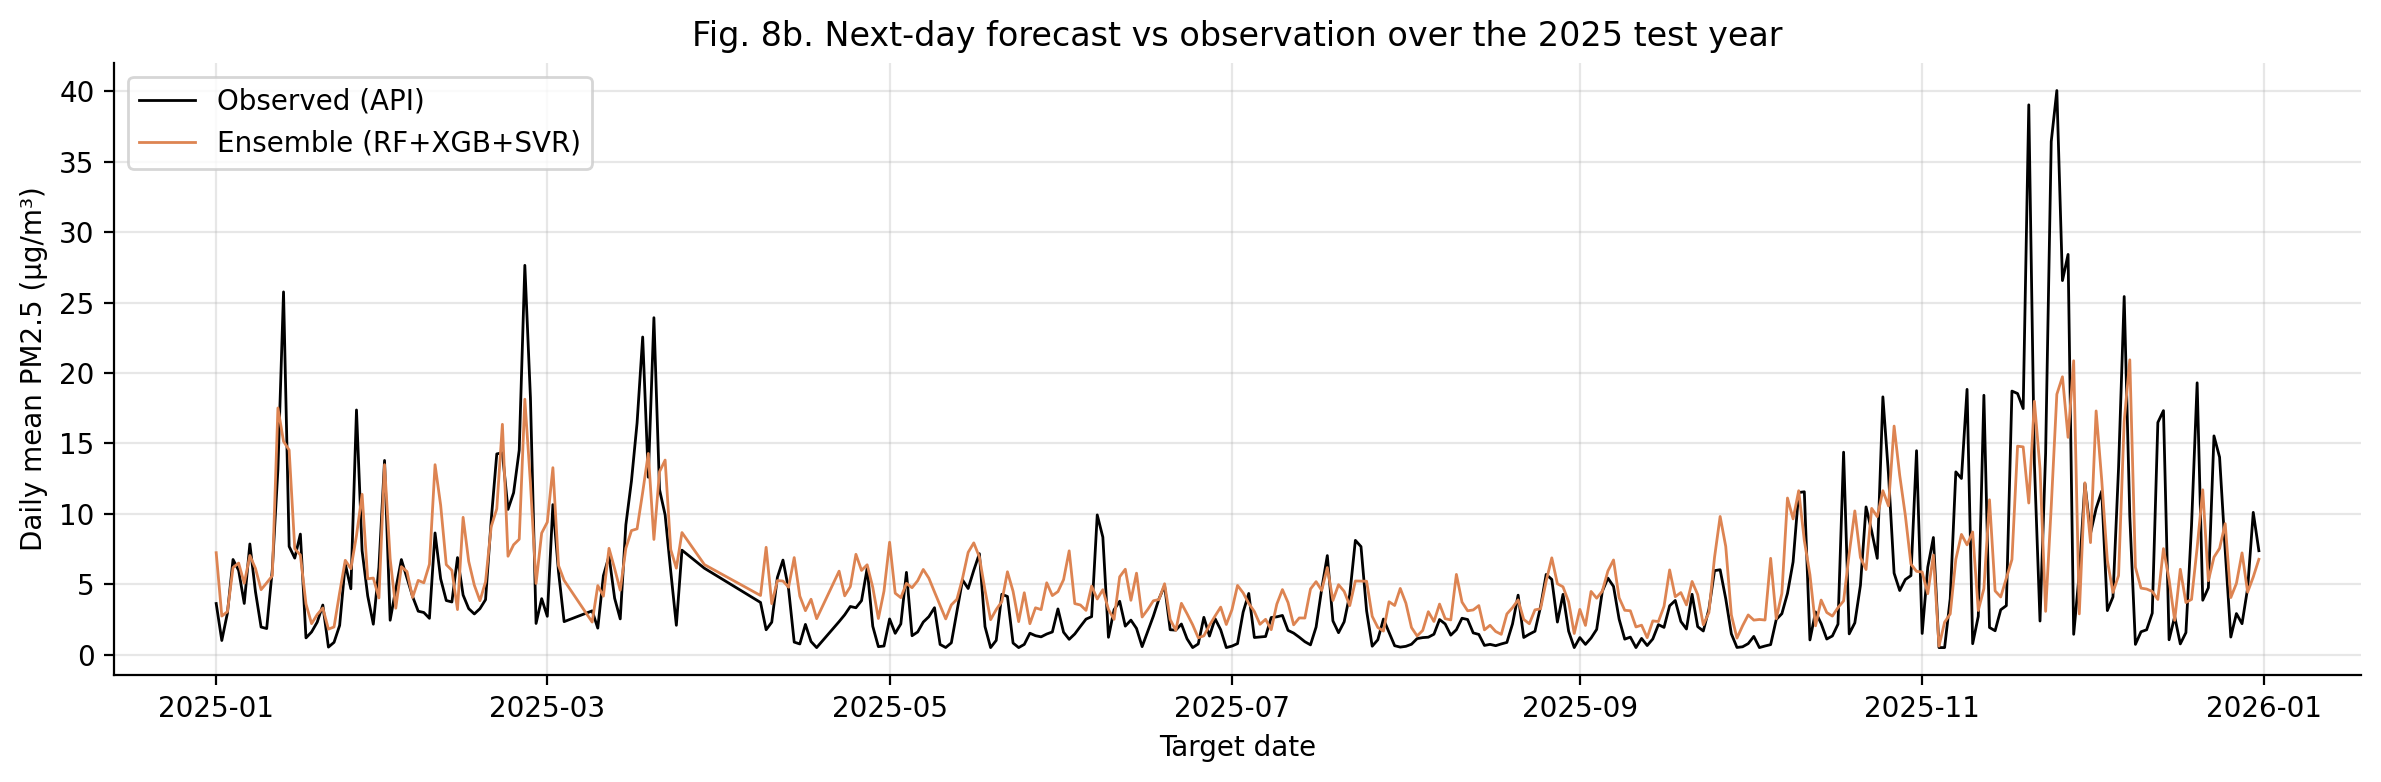

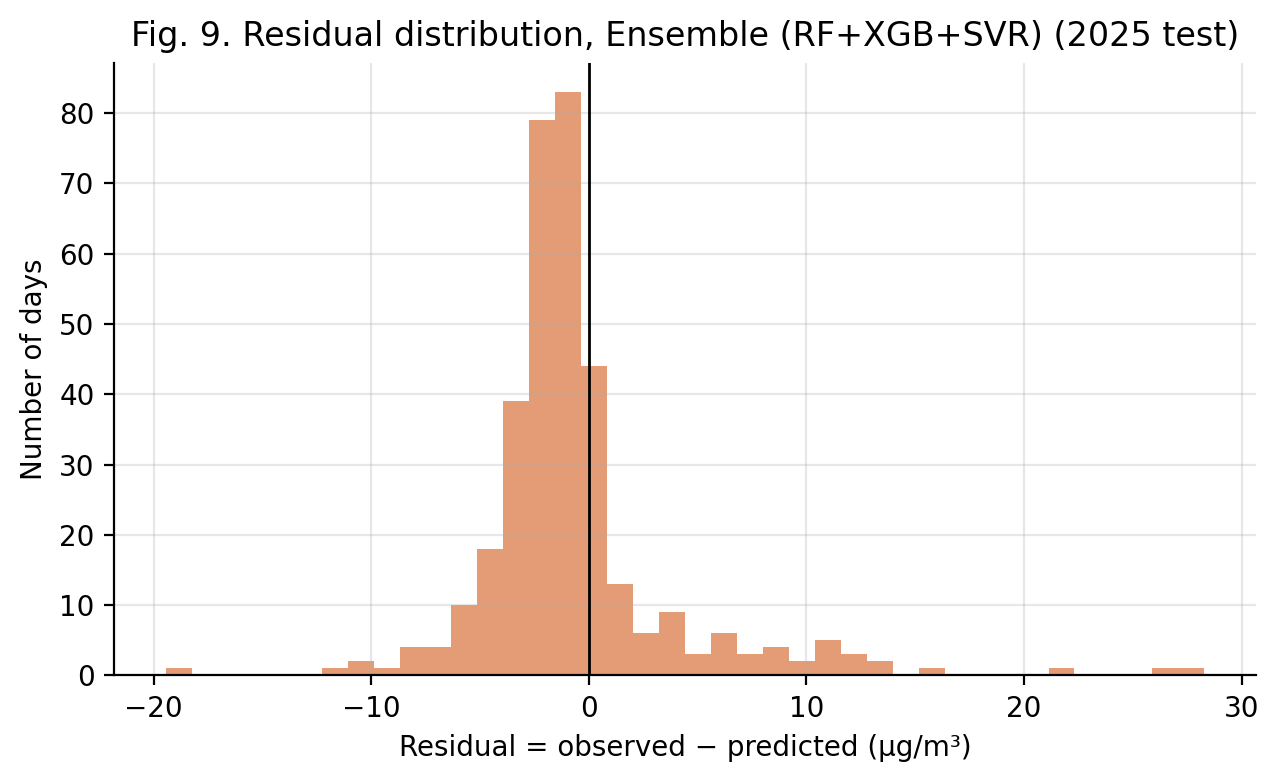

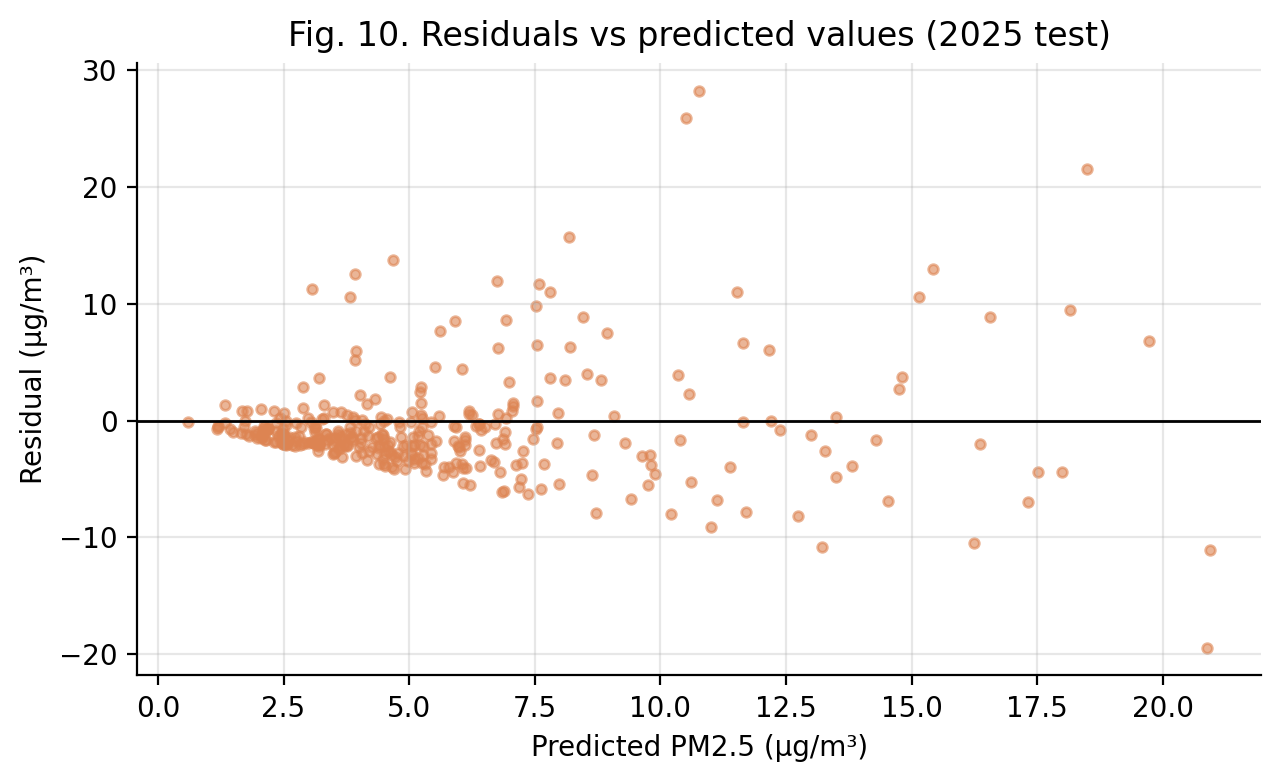

,issue_time_local,target_date,actual,predicted,abs_error
17258,2025-11-19T18:00:00+05:00,2025-11-20,39.05,10.77,28.28
17262,2025-11-23T18:00:00+05:00,2025-11-24,36.44,10.51,25.92
17263,2025-11-24T18:00:00+05:00,2025-11-25,40.06,18.49,21.57
17266,2025-11-27T18:00:00+05:00,2025-11-28,1.44,20.87,19.43
17028,2025-03-19T18:00:00+05:00,2025-03-20,23.93,8.18,15.75
17250,2025-11-11T18:00:00+05:00,2025-11-12,18.42,4.69,13.73
17265,2025-11-26T18:00:00+05:00,2025-11-27,28.42,15.43,12.99
17281,2025-12-12T18:00:00+05:00,2025-12-13,16.49,3.92,12.57
17255,2025-11-16T18:00:00+05:00,2025-11-17,18.72,6.76,11.96
17288,2025-12-19T18:00:00+05:00,2025-12-20,19.30,7.58,11.72


In [10]:
for f in ["08_actual_vs_predicted.png", "08b_test_timeseries.png", "09_residual_distribution.png", "10_residuals_vs_predicted.png"]:
    display(Image(FIG / f))
pt = pd.read_csv(cfg.path("predictions_dir") / "predictions_test.csv")
bt = pt[(pt.model == best["model"]) & (pt.feature_config == best["feature_config"]) & (pt.variant == "tuned")]
display(bt.nlargest(10, "abs_error")[["issue_time_local", "target_date", "actual", "predicted", "abs_error"]].round(2))

## Hypothesis evaluation (automatically derived from the results)

In [11]:
from air_quality.report import hypothesis_verdicts
for k, v in hypothesis_verdicts(cfg).items():
    print(f"{k}: {v}")

H1: Not supported: the lowest 2024 validation MAE was obtained by Ensemble (RF+XGB+SVR) (full_weather, 2.227 µg/m³).
H2: Supported: engineered features (best of lag/full) lowered validation MAE for 3 of 5 models (basic → engineered: Ensemble (RF+XGB+SVR) 3.105→3.091; Random Forest 3.116→3.118; Ridge Regression 3.405→3.225; SVR (RBF) 3.155→3.080; XGBoost 3.156→3.163).
H3: Supported: on the 2025 test the selected Ensemble (RF+XGB+SVR) obtained MAE 3.015 µg/m³ vs 3.516 µg/m³ for persistence (skill +0.142, i.e. +14.2% MAE change); 4 of 5 ML models beat persistence.
H4: Not supported: the three most important features of Ensemble (RF+XGB+SVR) by test-set permutation importance were pm25_last, pm10_last, target_month_cos (1 of 3 are PM2.5-history features). Importance is associational, not causal.
H5: Supported: on 33 elevated test days (> 13.2 µg/m³, training 90th percentile) the MAE of Ensemble (RF+XGB+SVR) was 9.937 vs 2.285 µg/m³ on other days (ratio 4.35); bias on elevated days -9.547 µ